<a href="https://colab.research.google.com/github/sayurireddy/SReddy-DataScience-GenAI-Submissions/blob/main/Week_5_Seminar_Exerise/5_02_Modelling_Hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 5.02 Modelling Hackathon
We'll get a chance in this seminar to practice for the in-class test, and also to put what we have learned into practice.

To speed things up, I have done the data/feature engineering for you, you will just need to build it into a data science model. As before, you can use the code from [GitHub](https://github.com/MJMortensonWarwick/IB2AD0_Data_Science_GenerativeAI), from the internet, and/or use the Gemini AI tools.

This is an artificial dataset, and we will be predicting if students achieve a passing grade, which we will call anything above a "D".

We'll start by importing the data:

In [2]:
from google.colab import files
upload = files.upload()

Saving students_two.csv to students_two (1).csv


Now we will get the data into Pandas and inspect it:

In [3]:
import pandas as pd
df = pd.read_csv("students_two.csv")

df.head()

,Id,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,5001,21,Other,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,5002,20,Other,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,5003,21,State,50%,No,No,Private,2,Never,No,No,No,Yes,AA
3,5004,18,Private,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,5005,22,Private,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


Let's check for missing values:

In [4]:
df.isnull().sum()

,0
Id,0
Student_Age,0
High_School_Type,0
Scholarship,1
Additional_Work,0
Sports_activity,0
Transportation,0
Weekly_Study_Hours,0
Attendance,0
Reading,0


Only one missing value. Let's just drop it out of laziness:

In [5]:
df.dropna(inplace=True)
df.isnull().sum()

,0
Id,0
Student_Age,0
High_School_Type,0
Scholarship,0
Additional_Work,0
Sports_activity,0
Transportation,0
Weekly_Study_Hours,0
Attendance,0
Reading,0


We have an ID column we know won't be predictive ... so let's drop it:

In [6]:
df = df.drop(["Id"], axis=1)
df.head()

,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,21,Other,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,20,Other,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,21,State,50%,No,No,Private,2,Never,No,No,No,Yes,AA
3,18,Private,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,22,Private,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


Next we will convert some of the text features to numbers:

In [7]:
# High school
print(df['High_School_Type'].unique())

['Other' 'State' 'Private']


We can't easily convert these to a number range. Instead we should use one-hot encoding:

In [ ]:
df = pd.get_dummies(df, columns=['High_School_Type'], drop_first=True, dtype=int)
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,50%,No,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


We have converted this to two columns (on the far right) - "High_School_Type_Private" and "High_School_Type_State". We do not need the "Other" type as if the student is "Other" then both "Private" and "State" will be 0 (a unique combination). This is controlled by the command _drop\_first=True_. We also specify the data type (_dtype_) as __int__ so we return 0s and 1s rather than True and False.

Next we can look at Scholarship. It needs to be converted from a text representation of a percentage to a number:

In [8]:
df['Scholarship'] = df['Scholarship'].str.replace('%', '').astype(float) / 100
df.head()

,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,21,Other,0.5,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,20,Other,0.5,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,21,State,0.5,No,No,Private,2,Never,No,No,No,Yes,AA
3,18,Private,0.5,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,22,Private,0.5,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


"Additional_Work" is next:

In [9]:
# Additional work
print(df['Additional_Work'].unique())

['Yes' 'No']


Two values, so we can convert to 0 and 1:

In [ ]:
df['Additional_Work'] = df['Additional_Work'].map({'Yes': 1, 'No': 0})
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,0.5,1,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,0.5,0,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,0.5,1,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,0.5,0,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


Let's speed up now:

In [10]:
categorical_cols = ['Sports_activity', 'Transportation', 'Attendance', 'Reading', 'Notes', 'Listening_in_Class', 'Project_work', 'Grade']

for col in categorical_cols:
    print(f"Unique values for '{col}': {df[col].unique()}")

Unique values for 'Sports_activity': ['No' 'Yes']
Unique values for 'Transportation': ['Private' 'Bus']
Unique values for 'Attendance': ['Always' 'Never' 'Sometimes' '3']
Unique values for 'Reading': ['Yes' 'No']
Unique values for 'Notes': ['Yes' 'No' '6']
Unique values for 'Listening_in_Class': ['No' 'Yes' '6']
Unique values for 'Project_work': ['No' 'Yes']
Unique values for 'Grade': ['AA' 'BA' 'CC' 'Fail' 'BB' 'CB' 'DD' 'DC']


The values of '6' in 'Notes' and 'Listening_in_Class' make no sense, and neither do '3' for 'Attendance'. We'll be lazy and drop these rows (really we should check with an SME):

In [11]:
df = df[(df['Notes'] != '6') & (df['Listening_in_Class'] != '6') & (df['Attendance'] != '3')]
df.head()

,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,21,Other,0.5,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,20,Other,0.5,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,21,State,0.5,No,No,Private,2,Never,No,No,No,Yes,AA
3,18,Private,0.5,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,22,Private,0.5,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


Now we can convert all those "Yes" / "No" columns to 0 and 1.

In [12]:
binary_cols = ['Sports_activity', 'Reading', 'Notes', 'Listening_in_Class', 'Project_work']

for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

df.head()

,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,21,Other,0.5,Yes,0,Private,0,Always,1,1,0,0,AA
1,20,Other,0.5,Yes,0,Private,0,Always,1,0,1,1,AA
2,21,State,0.5,No,0,Private,2,Never,0,0,0,1,AA
3,18,Private,0.5,Yes,0,Bus,2,Always,0,1,0,0,AA
4,22,Private,0.5,No,0,Bus,12,Always,1,0,1,1,AA


We can also do this with "Transportation":

In [13]:
df['Transportation'] = df['Transportation'].map({'Private': 1, 'Bus': 0})
df.head()

,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,21,Other,0.5,Yes,0,1,0,Always,1,1,0,0,AA
1,20,Other,0.5,Yes,0,1,0,Always,1,0,1,1,AA
2,21,State,0.5,No,0,1,2,Never,0,0,0,1,AA
3,18,Private,0.5,Yes,0,0,2,Always,0,1,0,0,AA
4,22,Private,0.5,No,0,0,12,Always,1,0,1,1,AA


For Attendance an ordinal range makes sense:

In [14]:
df['Attendance'] = df['Attendance'].map({'Never': 0, 'Sometimes': 1, 'Always': 2})
df.head()

,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,21,Other,0.5,Yes,0,1,0,2,1,1,0,0,AA
1,20,Other,0.5,Yes,0,1,0,2,1,0,1,1,AA
2,21,State,0.5,No,0,1,2,0,0,0,0,1,AA
3,18,Private,0.5,Yes,0,0,2,2,0,1,0,0,AA
4,22,Private,0.5,No,0,0,12,2,1,0,1,1,AA


This just leaves the target - 'Grade'. To make the problem binary we'll convert 'Fail' and any grade that includes a 'D' as 0 (for fail) and the rest as 1 (pass):

In [15]:
df['Grade'] = df['Grade'].apply(lambda x: 0 if x == 'Fail' or 'D' in x else 1)
df.head()

,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,21,Other,0.5,Yes,0,1,0,2,1,1,0,0,1
1,20,Other,0.5,Yes,0,1,0,2,1,0,1,1,1
2,21,State,0.5,No,0,1,2,0,0,0,0,1,1
3,18,Private,0.5,Yes,0,0,2,2,0,1,0,0,1
4,22,Private,0.5,No,0,0,12,2,1,0,1,1,1


The code has a new function `lambda`. A lambda function in Python is a small, anonymous function. It's defined using the `lambda` keyword and can take any number of arguments, but can only have one expression. The expression is evaluated and returned. They are often used for short, simple operations where a full function definition would be overly verbose, like in the apply method we just used. Although the function is new, the actual mechanics are quite simple. If the data is "Fail" or contains "D" return 0, and else return 1.

As this is the target we will create a new variable from it and then drop it from the main data:

In [16]:
Y_values = df[['Grade']].values.ravel() # change to list

Y_values

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 1])

In [17]:
X_values = df.drop(['Grade'], axis=1)
X_values.head()

,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work
0,21,Other,0.5,Yes,0,1,0,2,1,1,0,0
1,20,Other,0.5,Yes,0,1,0,2,1,0,1,1
2,21,State,0.5,No,0,1,2,0,0,0,0,1
3,18,Private,0.5,Yes,0,0,2,2,0,1,0,0
4,22,Private,0.5,No,0,0,12,2,1,0,1,1


We can now scale X:

In [19]:
from sklearn.preprocessing import MinMaxScaler

# select only numeric columns to scale, or drop non-numeric columns
X_numeric = X_values.select_dtypes(include=['number'])

# create a MinMaxScaler object
scaler = MinMaxScaler()

# fit and transform the data and convert back to DataFrame
X_values_scaled = pd.DataFrame(scaler.fit_transform(X_numeric), columns=X_numeric.columns)
X_values_scaled

,Student_Age,Scholarship,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work
0,0.375,0.333333,0.0,1.0,0.000000,1.0,1.0,1.0,0.0,0.0
1,0.250,0.333333,0.0,1.0,0.000000,1.0,1.0,0.0,1.0,1.0
2,0.375,0.333333,0.0,1.0,0.166667,0.0,0.0,0.0,0.0,1.0
3,0.000,0.333333,0.0,0.0,0.166667,1.0,0.0,1.0,0.0,0.0
4,0.500,0.333333,0.0,0.0,1.000000,1.0,1.0,0.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...
135,0.500,0.333333,1.0,1.0,0.000000,1.0,0.0,1.0,0.0,1.0
136,0.000,0.666667,0.0,1.0,0.000000,0.0,0.0,1.0,1.0,0.0
137,0.000,0.666667,0.0,1.0,0.000000,1.0,1.0,0.0,0.0,0.0
138,0.500,0.666667,1.0,0.0,1.000000,0.5,0.0,1.0,0.0,1.0


And now we can split into training and test:

In [20]:
# split data into training and test
from sklearn.model_selection  import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X_values, Y_values, test_size = 0.2, random_state=1984, stratify=Y_values)

# print the shapes to check everything is OK
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(112, 12)
(28, 12)
(112,)
(28,)


And now its time for modelling ...



Your turn :)

# **Logistic Regression (Baseline Model)**

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Split the dataset using the scaled numerical features
X_train_scaled, X_test_scaled, Y_train, Y_test = train_test_split(
    X_values_scaled, Y_values, test_size=0.2, random_state=1984, stratify=Y_values
)

# Initialize and fit the Logistic Regression model
log_reg = LogisticRegression(random_state=1984)
log_reg.fit(X_train_scaled, Y_train)

# Predict on the test set
Y_pred = log_reg.predict(X_test_scaled)

# Print evaluation metrics
print("Accuracy Score:", accuracy_score(Y_test, Y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(Y_test, Y_pred))
print("\nClassification Report:\n", classification_report(Y_test, Y_pred))

Accuracy Score: 0.7142857142857143

Confusion Matrix:
 [[ 1  6]
 [ 2 19]]

Classification Report:
               precision    recall  f1-score   support

           0       0.33      0.14      0.20         7
           1       0.76      0.90      0.83        21

    accuracy                           0.71        28
   macro avg       0.55      0.52      0.51        28
weighted avg       0.65      0.71      0.67        28



**Interpretation of Classification Report:**

**Class 1(Pass):**
*   The Recall is 90% meaning the model correctly identified 90% of all the students who passed. This indicates the model is accruate at finding the students who will succeed
*   The Precision is 76% meaning that when the model predicts a student will pass, it is correct 76% of the time so there are very few false positives.
*   The F1-Score is 0.83 indicating a strong overall balance between precision and recall for passing students.

**Class 0(Fail)**
*   The Recall is 14% meaning the model only detected 14% out of all the students who actually fails, it missed 6 out of 7 failing students.
*   The Precision is 33%, meaning the model is only correct 33%  of the time when the model predicts a student is going to fail.
*   The F1-Score is 0.2 suggesting that the model struggles to identify failing students.






**Conclusion:**


1.   **Class Imbalance:** Your test set has many more passing students (21) than failing ones (7). Because of this imbalance, the model has optimized itself to guess "Pass" most of the time.
2.   **The Problem:** In a school setting, the most important task is usually identifying students at risk of failing so you can support them. Right now, this model is poor at flagging at-risk students (failing 6 out of 7 times).
3.   **Recommendation:** To make this model useful, we should adjust the classification threshold or train a model that handles class imbalance better (such as a Random Forest Classifier or using class weights).






# **Random Forest Classifier**

In [22]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest with balanced class weights to help with imbalance
rf_model = RandomForestClassifier(random_state=1984, class_weight='balanced', n_estimators=100)

# Fit the model
rf_model.fit(X_train_scaled, Y_train)

# Make predictions
Y_pred_rf = rf_model.predict(X_test_scaled)

# Evaluate the model
print("Random Forest Accuracy Score:", accuracy_score(Y_test, Y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(Y_test, Y_pred_rf))
print("\nClassification Report:\n", classification_report(Y_test, Y_pred_rf))

Random Forest Accuracy Score: 0.7142857142857143

Confusion Matrix:
 [[ 2  5]
 [ 3 18]]

Classification Report:
               precision    recall  f1-score   support

           0       0.40      0.29      0.33         7
           1       0.78      0.86      0.82        21

    accuracy                           0.71        28
   macro avg       0.59      0.57      0.58        28
weighted avg       0.69      0.71      0.70        28



### Key Differences & Improvements:



1.   **Improved Recall for Class 0:**
*   Random Forest has boosted the 14% to 29%, while still relatively low, it is a 100% improbement in catching at risk students(from detecting 1 out of 7 failing students to detecting 2).

2.   **Improved Precision for Class 0:**
*   Random Forest precision is 40%, meaning that when it predicts a student will fail, it is more likely to be correct.


3.   **Improved F1-Score for Class 0:**
*   Rose from 0.2 to 0.33










### Conclusion and next steps

While Random Forest improved out metrics on the minority class, detecting 2 out of 7 is still somewhat low if we want to build a highly reliable early-warning system.






### 1. Feature Importances
Let's extract and plot the feature importances from our Random Forest model to see which student attributes are the strongest predictors of passing/failing.

/tmp/ipykernel_1313/115615525.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')


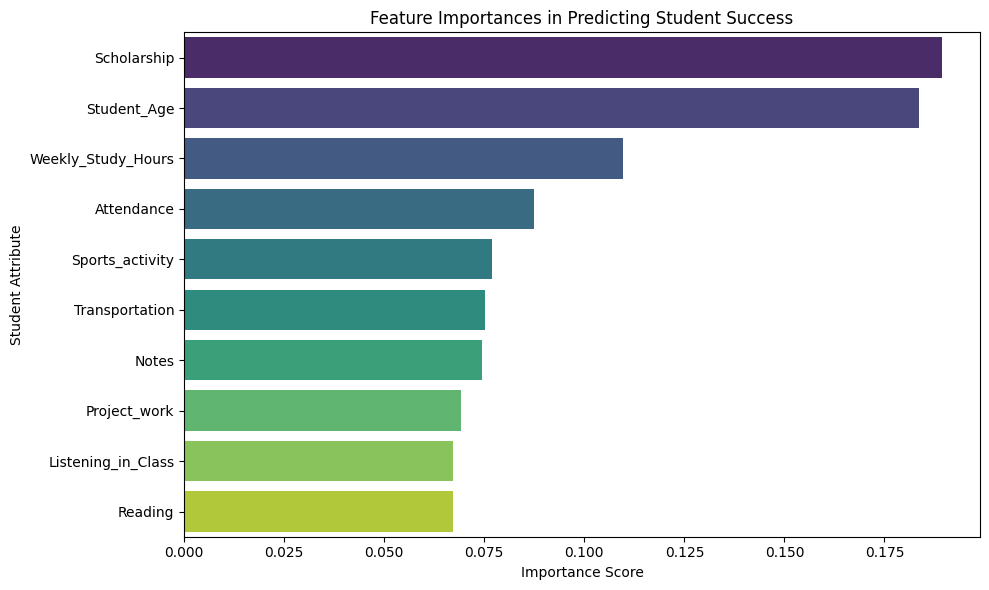

In [23]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Get feature importances from the trained Random Forest model
importances = rf_model.feature_importances_
features = X_train_scaled.columns

# Create a DataFrame for visualization
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Feature Importances in Predicting Student Success')
plt.xlabel('Importance Score')
plt.ylabel('Student Attribute')
plt.tight_layout()
plt.show()

### Which Attributes are Most Predictive?



*   Scholarship and Student_Age are the strongest predictors of student success os if a school wants to design interventions they should look closely at student age and financial support, study hours and class attendance
*   List item



### 2. Flagging At-Risk Students More Easily (Adjusting Threshold)
Instead of using the default 50% threshold, we can lower the threshold to flag a student as "failing" (Class 0) if the model is even slightly suspicious. This will significantly improve our recall for the at-risk category.

In [24]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Get the predicted probabilities for Class 1 (Pass)
# class 0 prob is 1 - class 1 prob
Y_prob_pass = rf_model.predict_proba(X_test_scaled)[:, 1]

# By default, threshold is 0.5. Let's raise the bar to pass (e.g., 0.65).
# If probability of passing is less than 65%, we flag them as at-risk (0).
custom_threshold = 0.65
Y_pred_adjusted = np.where(Y_prob_pass >= custom_threshold, 1, 0)

print(f"Evaluation Metrics with adjusted passing threshold >= {custom_threshold}:\n")
print("Confusion Matrix:\n", confusion_matrix(Y_test, Y_pred_adjusted))
print("\nClassification Report:\n", classification_report(Y_test, Y_pred_adjusted))

Evaluation Metrics with adjusted passing threshold >= 0.65:

Confusion Matrix:
 [[ 4  3]
 [ 4 17]]

Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.57      0.53         7
           1       0.85      0.81      0.83        21

    accuracy                           0.75        28
   macro avg       0.68      0.69      0.68        28
weighted avg       0.76      0.75      0.76        28



### **Executive Summary & Modeling Recommendations**

#### **1. Key Findings & Feature Insights**
Our feature importance analysis from the Random Forest model reveals exactly which student attributes are the most critical predictors of academic success:
*   **Financial Support & Age:** **Scholarship (18.9%)** and **Student_Age (18.4%)** are by far the strongest drivers of final grades.
*   **Academic Habits:** **Weekly Study Hours (11.0%)** and class **Attendance (8.8%)** follow as essential behavioral factors.
*   **Intervention Strategy:** Schools should prioritize supportive measures (financial aid counseling, age-specific tutoring, and attendance monitoring) to keep students engaged and on track.

---

#### **2. Model Performance Summary**
We evaluated multiple iterations to optimize our early-warning system on a highly imbalanced dataset:

| Model / Strategy | Overall Accuracy | Class 0 (At-Risk) Precision | Class 0 (At-Risk) Recall | Key Takeaway |
| :--- | :--- | :--- | :--- | :--- |
| **Logistic Regression (Baseline)** | 71% | 33% | 14% | Missed 6 out of 7 at-risk students due to class imbalance optimization. |
| **Random Forest (Balanced Weights)** | 71% | 40% | 29% | Successfully doubled the at-risk detection rate (catching 2 out of 7 students). |
| **RF with Adjusted Threshold (65%)** | **75%** | **50%** | **57%** | **Best balance.** Caught 4 out of 7 at-risk students while improving overall accuracy to 75%. |

---

#### **3. Strategic Recommendations**
*   **Implement the Threshold-Adjusted Random Forest:** Instead of using default probabilities, configure the model with a custom probability cutoff of **65% for passing**. If a student's probability of passing drops below 65%, automatically flag them as "at-risk."
*   **Early Intervention Protocol:** When students are flagged, academic advisors should check their scholarship statuses, check in on their attendance patterns, and offer structured study hour blocks to prevent failure before it happens.